In [2]:
import os
os.chdir("D:/tmp_workplace/dynamic_structure/250331/C_VRV/structure_feature_detection_evaluation/28S_rRNA_include")
import matplotlib.pyplot as plt
import numpy as np
from scipy import sparse
from scipy.stats import mannwhitneyu
import pandas as pd

In [3]:
matrix = np.zeros((1015,1015))
with open("28S_rRNA_merge_RICseq_10_KR_10_remake10_merge_5_KR_5_OEmask_fill_diagonal_filter_gaussian.bedpe","r") as f:
    for line in f:
        if "chrom" in line:
            continue
        else:
            sub = line.strip().split()
            left = int(sub[1])
            right = int(sub[4])
            if left < right:
                matrix[int(left/5),int(right/5)] = 1
                matrix[int(right/5),int(left/5)] = 1

In [4]:
pairs = []
with open("28S_rRNA_c.bedpe","r")as f:
    for line in f:
        if "chrom" in line:
            continue
        else:
            sub = line.strip().split()
            left = int(sub[1])
            right = int(sub[4])
            if left < right:
                pairs.append((left,right))

In [5]:
sup = []
wsup = []

for pair in pairs:
    left = pair[0]
    right = pair[1]
    if matrix[int(left/5),int(right/5)] == 1:
        sup.append(pair)
    else:
        wsup.append(pair)

print(len(pairs),len(sup),len(wsup))

1495 1251 244


In [8]:
def get_matrix_npz(M1,M2):
    '''
    use rri-matrix dump result to creat matrix 
    '''
    S1 = sparse.coo_matrix((M1['value'],(np.asarray(M1['S'], dtype= 'i4'),np.asarray(M1['E'], dtype= 'i4')))).toarray()
    S2 = sparse.coo_matrix((M2['value'],(np.asarray(M2['E'], dtype= 'i4'),np.asarray(M2['S'], dtype= 'i4')))).toarray()
    matrix = np.zeros((max(S1.shape),max(S1.shape)))
    matrix[np.nonzero(S1)] = S1[np.nonzero(S1)]
    matrix[np.nonzero(S2)] = S2[np.nonzero(S2)]
    return matrix

def extract_matrix(file_name,res):
    data = np.loadtxt(file_name, usecols=[0,1,2], dtype=[('S','<i4'),('E','<i4'),('value','<f8')])
    data['S'] = data['S'] / res
    data['E'] = data['E'] / res
    data['value'][data['value'] < 0] = 0
    data['value'][np.isnan(data['value'])] = 0
    matrix = get_matrix_npz(data,data)
    return matrix

In [ ]:
rri = extract_matrix("28S_rRNA_merge_RICseq_5_KR.matrix",5)

In [12]:
supv = []
wsupv = []

for pair in sup:
    left = pair[0]
    right = pair[1]
    supv.append(rri[int(left/5),int(right/5)])

for pair in wsup:
    left = pair[0]
    right = pair[1]
    wsupv.append(rri[int(left/5),int(right/5)])

print(np.median(supv),np.median(wsupv))

601.63116 6.6605864


In [ ]:
all_data = [supv, wsupv]

group_names = ['supv', 'wsupv']

def perform_targeted_comparisons(data_list, names, alpha=0.05):
    comparisons = [
        (0, 1, 'supv vs wsupv')
    ]
    
    results = []

    print("=" * 70)
    print("n:")
    for i, name in enumerate(names):
        print(f"{name}: n = {len(data_list[i])}")
    
    print("=" * 70)
    print("result:")
    print("=" * 70)
    
    for idx1, idx2, comp_name in comparisons:
        data1 = data_list[idx1]
        data2 = data_list[idx2]
        n1 = len(data1)
        n2 = len(data2)
        
        stat, p_val = mannwhitneyu(data1, data2, alternative='two-sided')
        
        effect_r = 1 - (2 * stat) / (n1 * n2)
        
        median1 = np.median(data1)
        median2 = np.median(data2)
        mean1 = np.mean(data1)
        mean2 = np.mean(data2)
        iqr1 = np.percentile(data1, 75) - np.percentile(data1, 25)
        iqr2 = np.percentile(data2, 75) - np.percentile(data2, 25)
        
        n_boot = 1000
        boot_diffs = []
        for _ in range(n_boot):
            sample1 = np.random.choice(data1, size=len(data1), replace=True)
            sample2 = np.random.choice(data2, size=len(data2), replace=True)
            boot_diffs.append(np.median(sample1) - np.median(sample2))
        
        ci_low = np.percentile(boot_diffs, 2.5)
        ci_high = np.percentile(boot_diffs, 97.5)
        
        results.append({
            'Comparison': comp_name,
            'U_Statistic': stat,
            'P_Value': p_val,
            'Effect_Size_r': effect_r,
            'n1': n1,
            'n2': n2,
            'Median1': median1,
            'Median2': median2,
            'Median_Diff': median1 - median2,
            'Median_Diff_CI': f"[{ci_low:.3f}, {ci_high:.3f}]",
            'Mean1': mean1,
            'Mean2': mean2,
            'IQR1': iqr1,
            'IQR2': iqr2,
            'Significant': p_val < alpha
        })
        
        print(f"{comp_name}: U = {stat:.0f}, p = {p_val:.3e}, r = {effect_r:.3f}")
        print(f"  n: {names[idx1]}={n1}, {names[idx2]}={n2}")
        print(f"  median: {names[idx1]}={median1:.3f}, {names[idx2]}={median2:.3f}")
        print(f"  median_diff: {median1 - median2:.3f} (95% CI: [{ci_low:.3f}, {ci_high:.3f}])")
        print(f"  r: |r| = {abs(effect_r):.3f}")
    
    results_df = pd.DataFrame(results)
    
    results_df['Sig_Marker'] = results_df['P_Value'].apply(
        lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    )
    
    print("\n" + "=" * 70)
    print("summary:")
    print("=" * 70)
    
    return results_df

alpha = 0.05
results_df = perform_targeted_comparisons(all_data, group_names, alpha=alpha)

print("\ntable:")
print("=" * 70)
print(results_df.to_string(index=False))

print("\n (α = 0.05):")
print("=" * 70)
for _, row in results_df.iterrows():
    print(f"{row['Comparison']}: {row['Sig_Marker']} (p = {row['P_Value']:.3e})")

print("=" * 70)
for _, row in results_df.iterrows():
    effect_size = abs(row['Effect_Size_r'])
    print(f"{row['Comparison']}: |r| = {effect_size:.3f}")

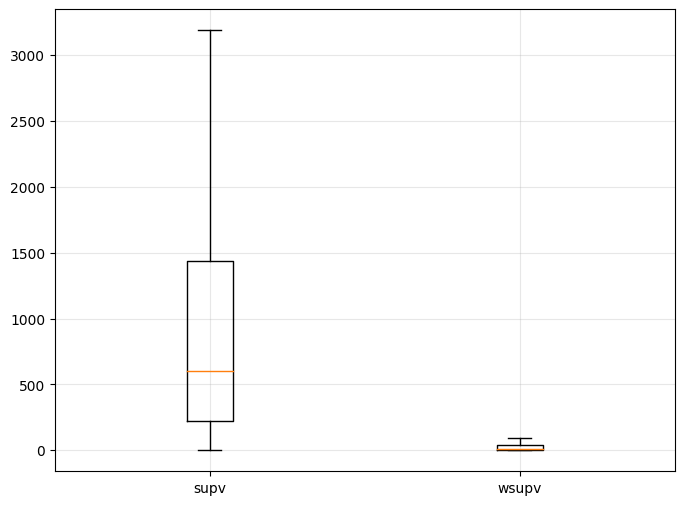

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
plt.boxplot([supv, wsupv], labels=['supv', 'wsupv'], showfliers=False)
plt.grid(True, alpha=0.3)
plt.savefig("include.pdf", format="pdf")
plt.show()